In [ ]:
!pip install pandas numpy matplotlib seaborn

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

print("All libraries imported successfully!")

All libraries imported successfully!


In [ ]:
import os

print("Current directory:", os.getcwd())

print("\nFiles available:")
print(os.listdir('/content'))

Current directory: /content

Files available:
['.config', 'Synthetic_pharmacy_sales_sample (1).csv', '.ipynb_checkpoints', 'sample_data']


In [ ]:
import glob
import pandas as pd

csv_files = glob.glob('/content/**/*.csv', recursive=True)

print("CSV files found:", csv_files)

if csv_files:
    df = pd.read_csv(csv_files[0])
    print("\nDataset loaded successfully!")
    display(df.head())
else:
    print("CSV file not found. Please upload it again.")

CSV files found: ['/content/Synthetic_pharmacy_sales_sample (1).csv', '/content/sample_data/california_housing_test.csv', '/content/sample_data/california_housing_train.csv', '/content/sample_data/mnist_test.csv', '/content/sample_data/mnist_train_small.csv']

Dataset loaded successfully!


,Date,Product,Category,Brand_Type,Quantity,Sales,Cost,Stock
0,2026-01-03,Paracetamol 500mg,Pain Relief,Generic,120,2400,1440,180
1,2026-01-05,Ibuprofen 200mg,Pain Relief,Branded,65,1950,1170,42
2,2026-01-08,Cetirizine 10mg,Allergy,Generic,90,1350,810,95
3,2026-01-12,Vitamin C 500mg,Vitamins,Branded,48,2400,1440,28
4,2026-01-16,ORS Sachets,Hydration,Generic,110,1650,990,210


In [ ]:
print("Rows and Columns:", df.shape)
print("\nColumn Names:")
print(df.columns.tolist())

Rows and Columns: (36, 8)

Column Names:
['Date', 'Product', 'Category', 'Brand_Type', 'Quantity', 'Sales', 'Cost', 'Stock']


In [ ]:
# Check dataset information
print("DATASET INFORMATION")
df.info()

# Check missing values
print("\nMISSING VALUES")
print(df.isnull().sum())

# Check duplicate records
print("\nDUPLICATE RECORDS")
print(df.duplicated().sum())

# Statistical summary
print("\nSTATISTICAL SUMMARY")
display(df.describe())

DATASET INFORMATION
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 36 entries, 0 to 35
Data columns (total 8 columns):
 #   Column      Non-Null Count  Dtype 
---  ------      --------------  ----- 
 0   Date        36 non-null     object
 1   Product     36 non-null     object
 2   Category    36 non-null     object
 3   Brand_Type  36 non-null     object
 4   Quantity    36 non-null     int64 
 5   Sales       36 non-null     int64 
 6   Cost        36 non-null     int64 
 7   Stock       36 non-null     int64 
dtypes: int64(4), object(4)
memory usage: 2.4+ KB

MISSING VALUES
Date          0
Product       0
Category      0
Brand_Type    0
Quantity      0
Sales         0
Cost          0
Stock         0
dtype: int64

DUPLICATE RECORDS
0

STATISTICAL SUMMARY


,Quantity,Sales,Cost,Stock
count,36.000000,36.000000,36.000000,36.000000
mean,89.194444,2684.722222,1666.944444,65.944444
std,40.022008,798.153176,540.031425,60.357007
min,35.000000,1350.000000,810.000000,6.000000
25%,51.500000,2017.500000,1210.500000,17.500000
50%,87.000000,2640.000000,1584.000000,40.500000
75%,120.500000,3315.000000,2142.000000,102.250000
max,172.000000,4410.000000,2646.000000,210.000000


In [ ]:
# Create a cleaned copy
df_clean = df.copy()

# Convert date column
df_clean['Date'] = pd.to_datetime(
    df_clean['Date'], errors='coerce'
)

# Convert numeric columns
numeric_cols = ['Quantity', 'Sales', 'Cost', 'Stock']

for col in numeric_cols:
    df_clean[col] = pd.to_numeric(
        df_clean[col], errors='coerce'
    )

# Remove extra spaces from text columns
text_cols = ['Product', 'Category', 'Brand_Type']

for col in text_cols:
    df_clean[col] = df_clean[col].astype('string').str.strip()

# Remove duplicate records
df_clean = df_clean.drop_duplicates()

# Remove rows missing essential information
df_clean = df_clean.dropna(
    subset=['Date', 'Product', 'Category',
            'Brand_Type', 'Quantity', 'Sales', 'Cost', 'Stock']
)

print("Data cleaning completed!")
print("Original records:", len(df))
print("Cleaned records:", len(df_clean))

display(df_clean.head())

Data cleaning completed!
Original records: 36
Cleaned records: 36


,Date,Product,Category,Brand_Type,Quantity,Sales,Cost,Stock
0,2026-01-03,Paracetamol 500mg,Pain Relief,Generic,120,2400,1440,180
1,2026-01-05,Ibuprofen 200mg,Pain Relief,Branded,65,1950,1170,42
2,2026-01-08,Cetirizine 10mg,Allergy,Generic,90,1350,810,95
3,2026-01-12,Vitamin C 500mg,Vitamins,Branded,48,2400,1440,28
4,2026-01-16,ORS Sachets,Hydration,Generic,110,1650,990,210


In [ ]:
# Calculate profit
df_clean['Profit'] = (
    df_clean['Sales'] - df_clean['Cost']
)

# Calculate profit margin
df_clean['Profit_Margin'] = (
    df_clean['Profit'] /
    df_clean['Sales'].replace(0, np.nan)
) * 100

# Extract month
df_clean['Month'] = df_clean['Date'].dt.strftime('%B')

print("TOTAL REVENUE:", df_clean['Sales'].sum())

print("TOTAL COST:", df_clean['Cost'].sum())

print("TOTAL PROFIT:", df_clean['Profit'].sum())

print("TOTAL QUANTITY:", df_clean['Quantity'].sum())

display(df_clean.head())

TOTAL REVENUE: 96650
TOTAL COST: 60010
TOTAL PROFIT: 36640
TOTAL QUANTITY: 3211


,Date,Product,Category,Brand_Type,Quantity,Sales,Cost,Stock,Profit,Profit_Margin,Month
0,2026-01-03,Paracetamol 500mg,Pain Relief,Generic,120,2400,1440,180,960,40.0,January
1,2026-01-05,Ibuprofen 200mg,Pain Relief,Branded,65,1950,1170,42,780,40.0,January
2,2026-01-08,Cetirizine 10mg,Allergy,Generic,90,1350,810,95,540,40.0,January
3,2026-01-12,Vitamin C 500mg,Vitamins,Branded,48,2400,1440,28,960,40.0,January
4,2026-01-16,ORS Sachets,Hydration,Generic,110,1650,990,210,660,40.0,January


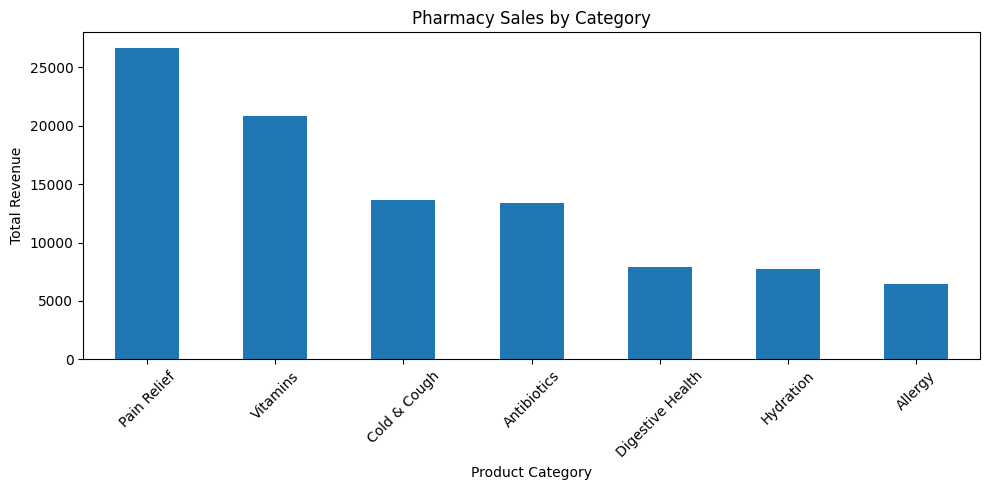

In [ ]:
category_sales = (
    df_clean.groupby('Category')['Sales']
    .sum()
    .sort_values(ascending=False)
)

plt.figure(figsize=(10, 5))

category_sales.plot(kind='bar')

plt.title('Pharmacy Sales by Category')
plt.xlabel('Product Category')
plt.ylabel('Total Revenue')

plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

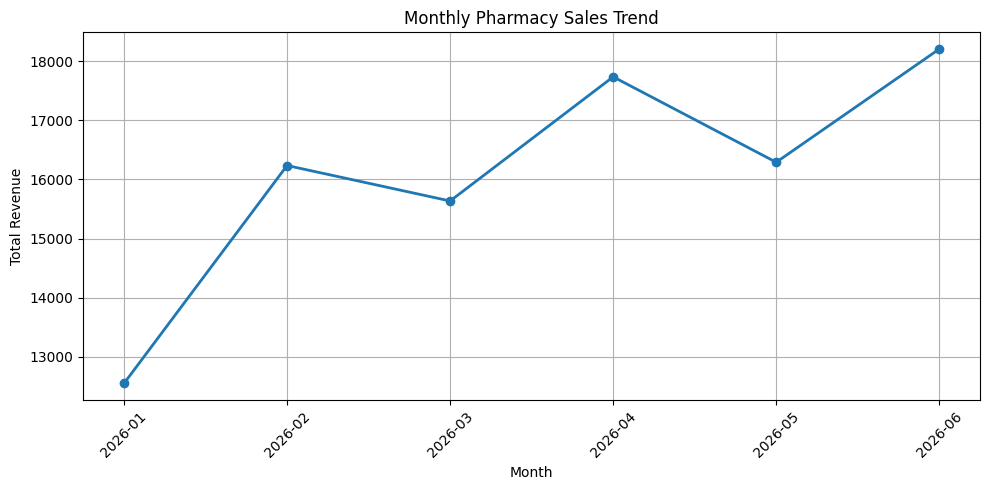

In [ ]:
# Monthly Sales Trend

df_clean['Date'] = pd.to_datetime(df_clean['Date'])

monthly_sales = (
    df_clean.groupby(df_clean['Date'].dt.to_period('M'))['Sales']
    .sum()
)

plt.figure(figsize=(10, 5))

plt.plot(
    monthly_sales.index.astype(str),
    monthly_sales.values,
    marker='o',
    linewidth=2
)

plt.title('Monthly Pharmacy Sales Trend')
plt.xlabel('Month')
plt.ylabel('Total Revenue')
plt.xticks(rotation=45)
plt.grid(True)
plt.tight_layout()
plt.show()

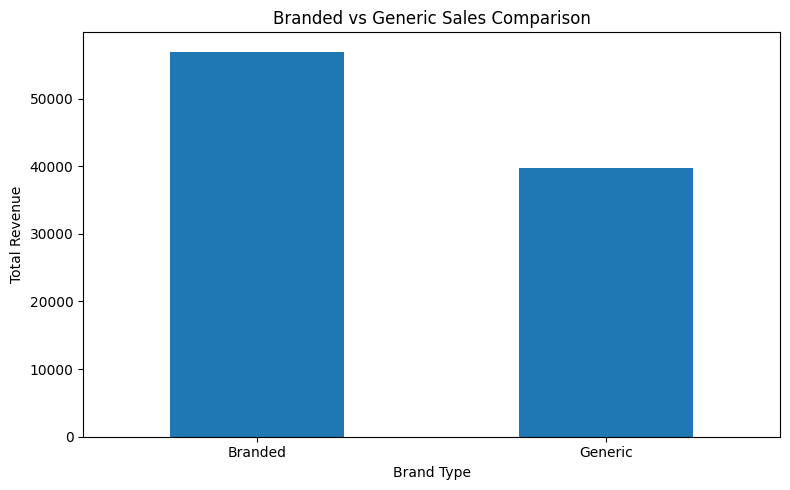

Brand_Type
Branded    56940
Generic    39710
Name: Sales, dtype: int64


In [ ]:
brand_sales = df_clean.groupby('Brand_Type')['Sales'].sum()

plt.figure(figsize=(8, 5))

brand_sales.plot(
    kind='bar',
    title='Branded vs Generic Sales Comparison'
)

plt.xlabel('Brand Type')
plt.ylabel('Total Revenue')
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

print(brand_sales)

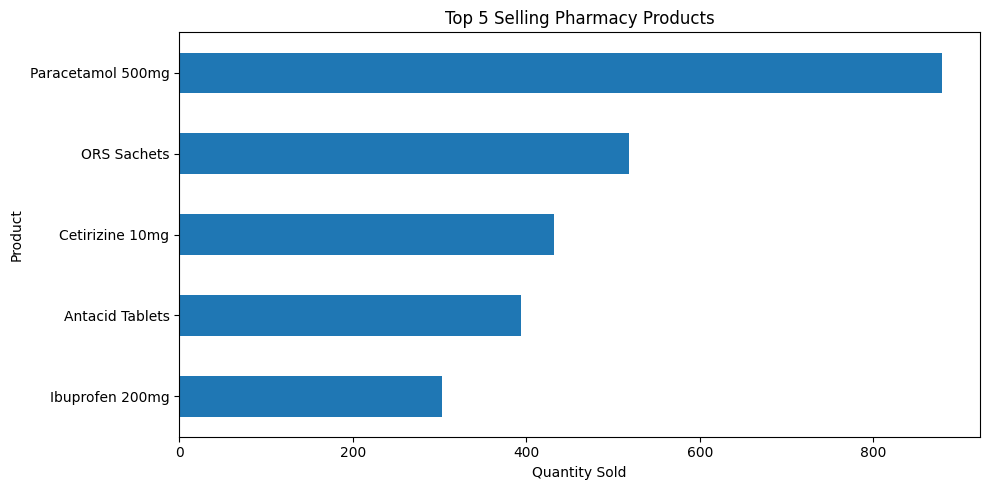

In [ ]:
top_products = (
    df_clean.groupby('Product')['Quantity']
    .sum()
    .nlargest(5)
)

plt.figure(figsize=(10, 5))

top_products.sort_values().plot(kind='barh')

plt.title('Top 5 Selling Pharmacy Products')
plt.xlabel('Quantity Sold')
plt.ylabel('Product')
plt.tight_layout()
plt.show()

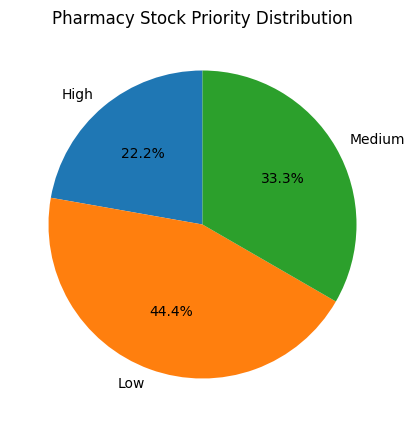

,Product,Stock,Stock_Priority
26,Vitamin C 500mg,16,Medium
28,Cetirizine 10mg,61,Low
29,Cough Syrup 100ml,8,High
30,ORS Sachets,145,Low
31,Amoxicillin 250mg,6,High
32,Paracetamol 500mg,98,Low
33,Multivitamin Tablets,14,Medium
34,Ibuprofen 200mg,25,Medium
35,Antacid Tablets,39,Low


In [ ]:
latest_stock = (
    df_clean.sort_values('Date')
    .groupby('Product')
    .tail(1)
    .copy()
)

latest_stock['Stock_Priority'] = np.select(
    [
        latest_stock['Stock'] < 10,
        latest_stock['Stock'] < 30
    ],
    ['High', 'Medium'],
    default='Low'
)

stock_summary = latest_stock.groupby(
    'Stock_Priority'
)['Product'].count()

plt.figure(figsize=(7, 5))

stock_summary.plot(
    kind='pie',
    autopct='%1.1f%%',
    startangle=90
)

plt.title('Pharmacy Stock Priority Distribution')
plt.ylabel('')
plt.show()

display(latest_stock[
    ['Product', 'Stock', 'Stock_Priority']
])

In [ ]:
total_revenue = df_clean['Sales'].sum()
total_cost = df_clean['Cost'].sum()
total_profit = total_revenue - total_cost
total_quantity = df_clean['Quantity'].sum()

profit_margin = (
    total_profit / total_revenue * 100
    if total_revenue else 0
)

print("====== PHARMACY PERFORMANCE REPORT ======")

print(f"Total Revenue: ₹{total_revenue:,.2f}")
print(f"Total Cost: ₹{total_cost:,.2f}")
print(f"Total Profit: ₹{total_profit:,.2f}")
print(f"Total Quantity Sold: {total_quantity:,}")
print(f"Profit Margin: {profit_margin:.2f}%")

print("\nBest Performing Category:")
print(df_clean.groupby('Category')['Sales'].sum().idxmax())

print("\nBest Selling Product:")
print(df_clean.groupby('Product')['Quantity'].sum().idxmax())

====== PHARMACY PERFORMANCE REPORT ======
Total Revenue: ₹96,650.00
Total Cost: ₹60,010.00
Total Profit: ₹36,640.00
Total Quantity Sold: 3,211
Profit Margin: 37.91%

Best Performing Category:
Pain Relief

Best Selling Product:
Paracetamol 500mg


In [ ]:
# Export cleaned dataset
df_clean.to_csv(
    'Pharmacy_Cleaned_Data.csv',
    index=False
)

# Download to your computer
from google.colab import files
files.download('Pharmacy_Cleaned_Data.csv')

print("Cleaned dataset exported successfully!")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

Cleaned dataset exported successfully!
